# 1. Data and validation

Energy burden comes from the DOE LEAD Tool (2022), explanatory variables from the 2018-2022 ACS.
This notebook shows how the sample was built, what each tract looks like, and how the LEAD-based
measure compares with ACEEE's published Chicago figures and with an independent ACS-based measure.
Script: `scripts/02_build.py`.

_Part of the Chicago Energy Burden project (James Rocco Quantitative Data Research Scholarship, Lake Forest College). Run the pipeline scripts first, or read the executed copy on GitHub._

In [1]:
import json, warnings
import numpy as np, pandas as pd, geopandas as gpd
from IPython.display import Image, Markdown, display
from ceb import config
warnings.filterwarnings("ignore")
pd.set_option("display.precision", 4)
T, F = config.TABLES, config.FIGURES
gdf = gpd.read_file(config.PROCESSED / "chicago_tracts.gpkg")
sample = gdf[gdf["in_main_sample"].astype(bool)].reset_index(drop=True)
print(f"{len(gdf)} tracts mostly inside Chicago; {len(sample)} in the analysis sample")

782 tracts mostly inside Chicago; 768 in the analysis sample


## Sample construction
Every tract that was flagged or dropped, and why.

In [2]:
display(Markdown((T / "exclusions.md").read_text()))

# Sample construction log

- Tracts with >= 50% of land area in Chicago: 782
- LEAD households dropped for zero/negative cohort income: 182
- LEAD households dropped because their cohort has no valid income data: 35,787
- LEAD households kept: 1,064,942
- no LEAD record: 3  
  `17031381700, 17031980000, 17031980100`
- fewer than 100 households: 3  
  `17031381700, 17031980000, 17031980100`
- a model covariate is missing: 14  
  `17031839500, 17031080400, 17031351400, 17031681000, 17031380100, 17031381700, 17031611800, 17031980000, 17031260400, 17031570200, 17031671900, 17031980100, 17031611600, 17031550100`
- an ACS covariate has CV > 0.4 (kept; dropped in robustness): 233
- **Main analysis sample: 768 tracts**


## Descriptive statistics (analysis sample)

In [3]:
cols = ["burden_pct", "li_burden_pct", "share_high", "share_severe", "avg_energy_cost", "med_hh_income",
        "pct_black", "pct_hispanic", "pct_pre1950", "pct_renter", "pct_multifam5", "households"]
sample[cols].describe().T[["mean", "std", "min", "50%", "max"]].round(2)

,mean,std,min,50%,max
burden_pct,3.30,1.97,0.47,2.88,10.72
li_burden_pct,7.19,2.54,1.70,7.07,19.07
share_high,0.31,0.20,0.01,0.28,0.86
share_severe,0.18,0.14,0.00,0.15,0.67
avg_energy_cost,2536.18,710.27,789.40,2605.66,5984.92
med_hh_income,74985.01,41801.10,13438.00,65267.00,250001.00
pct_black,33.45,38.19,0.00,8.35,100.00
pct_hispanic,26.96,28.08,0.00,14.85,98.83
pct_pre1950,51.16,20.42,0.59,53.25,94.33
pct_renter,53.84,20.74,0.99,55.82,100.00


## Benchmark check against ACEEE
ACEEE reports median household burdens; the citywide figure here is total spending over total income, so this is a sanity check, not an exact comparison.

In [4]:
city = 100 * sample["energy_total"].sum() / sample["income_total"].sum()
li = sample.dropna(subset=["li_burden_pct"])
li_city = 100 * li["li_energy_total"].sum() / li["li_income_total"].sum()
pd.DataFrame({"This study (LEAD 2022)": [city, li_city],
              "ACEEE 2024, Chicago": [config.ACEEE_2024_CHICAGO["all_households_median"],
                                      config.ACEEE_2024_CHICAGO["low_income_median"]]},
             index=["All households (%)", "Low-income households (%)"]).round(2)

,This study (LEAD 2022),"ACEEE 2024, Chicago"
All households (%),2.16,2.2
Low-income households (%),6.99,7.2


## Independent check: ACS utility-cost tables
If LEAD's modeling were driving the geography, an independent measure would rank tracts differently. It does not.

,n,pearson,spearman,top_quintile_overlap
burden,768.0,0.847,0.919,0.701
annual_cost,768.0,0.857,0.850,0.643


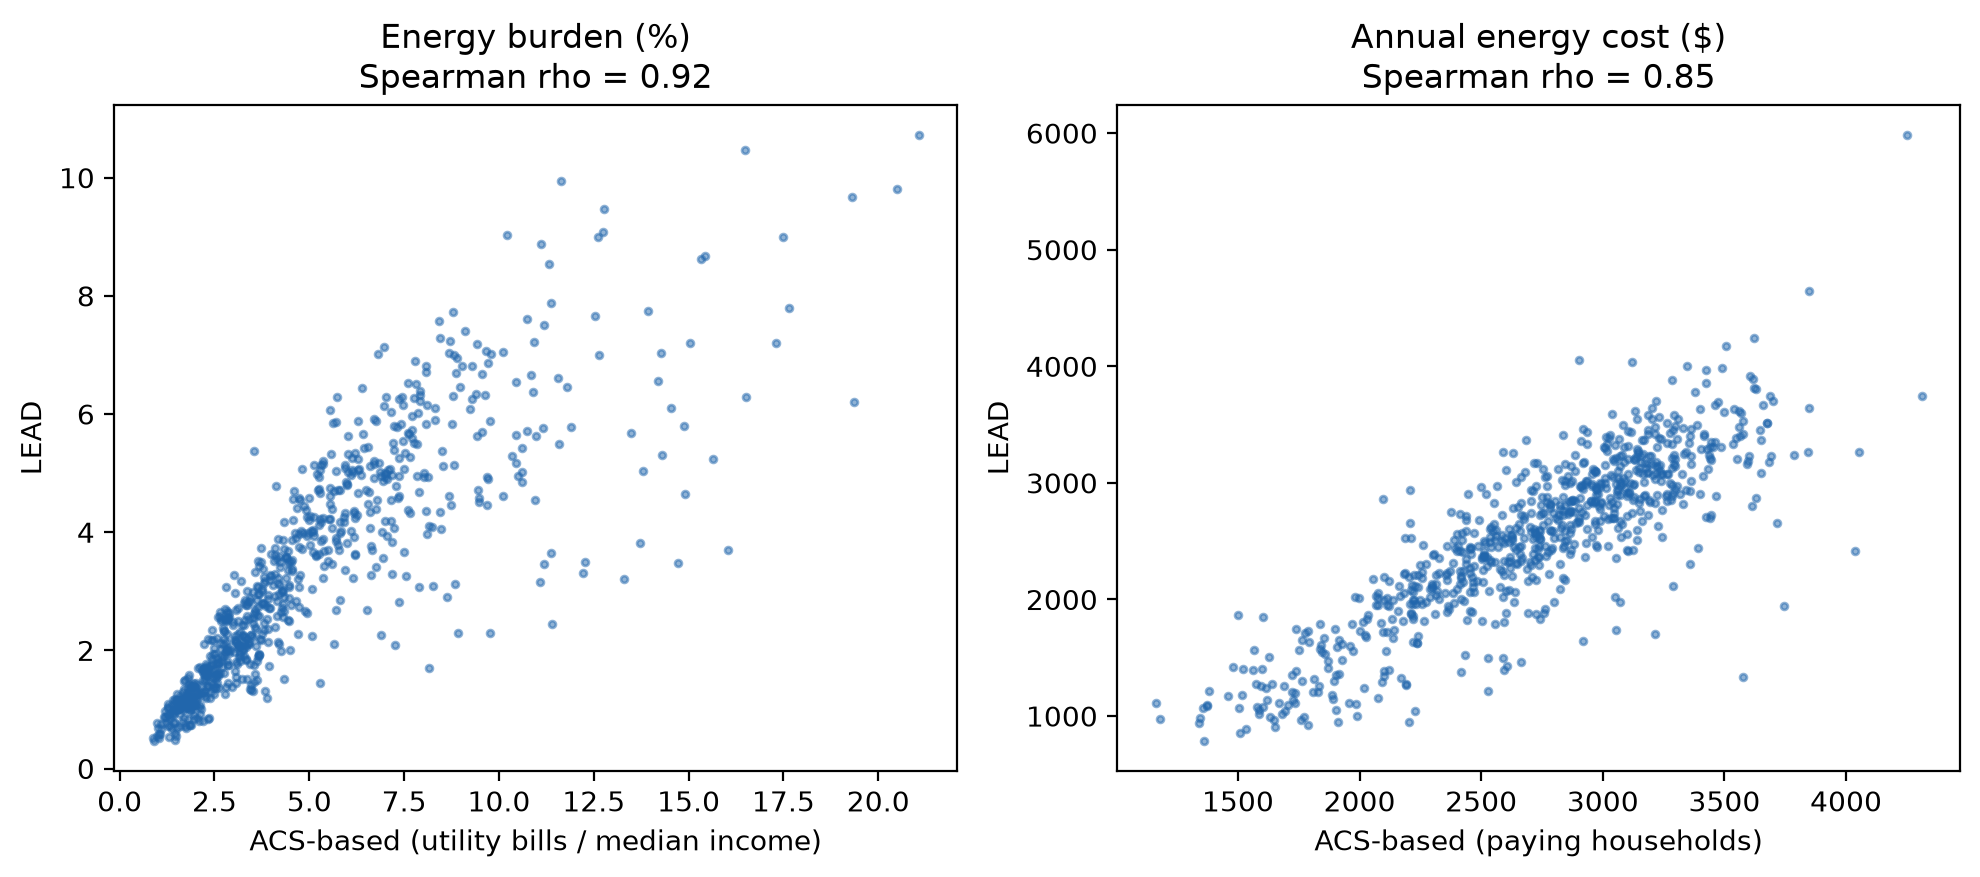

In [5]:
v = json.loads((T / "validation.json").read_text())
display(pd.DataFrame({k: v[k] for k in ("burden", "annual_cost") if k in v}).T.round(3))
if (F / "validation_scatter.png").exists(): display(Image(F / "validation_scatter.png", width=800))